#前置作業
認領表單:
https://docs.google.com/spreadsheets/d/14KsLdSk5APzaf7_SL-DyPEfNxuCY9Ju_aRnP5-4ju4E/edit?usp=sharing

永續報告書入口網頁
https://esggenplus.twse.com.tw/inquiry/report?lang=zh-TW

點擊 說明 -> 切換為英文

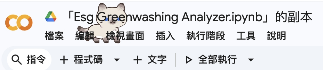

點擊 Runtime -> Change runtime type

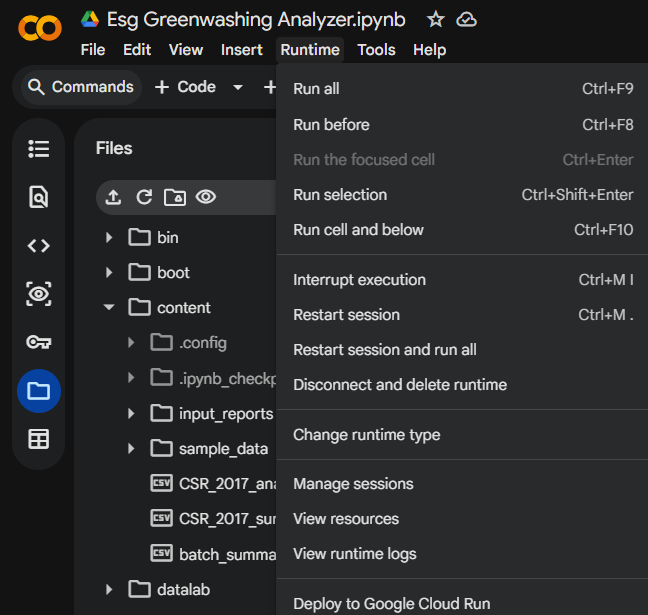

點擊 T4 GPU, 然後點擊 Save

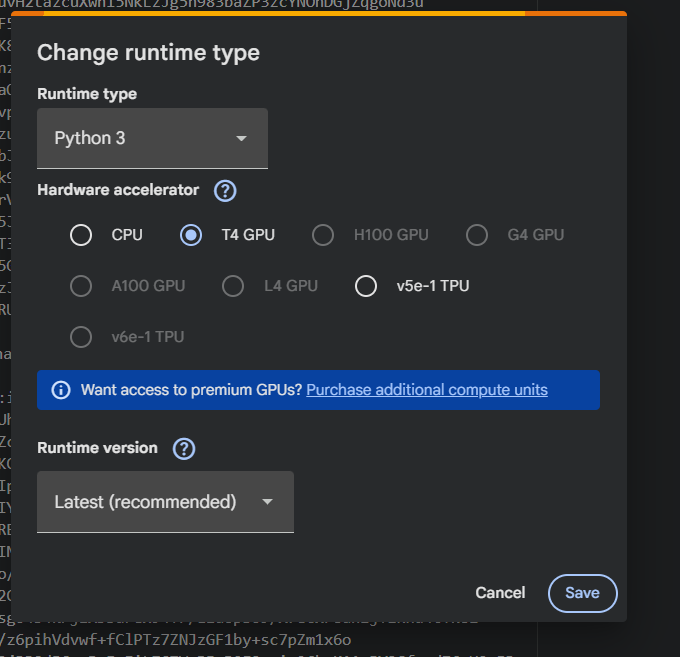


點擊這個標題左邊的符號以收起這個欄位底下的 cell
(符號朝右(>)表以收起, 只要在朝下時點擊它就好了)

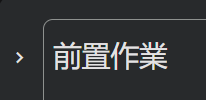

In [ ]:
!pip -q install transformers accelerate sentencepiece pymupdf scikit-learn pandas tqdm openpyxl
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-chi-tra tesseract-ocr-chi-sim poppler-utils
!pip -q install pytesseract pdf2image

In [ ]:
# 1. 匯入套件與 GPU 檢查
# =========================
import os
import re
import math
import json
from pathlib import Path
from typing import List, Dict, Any, Optional

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import torch
import fitz  # PyMuPDF

from sklearn.feature_extraction.text import TfidfVectorizer
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE = 0 if torch.cuda.is_available() else -1


In [ ]:
# 2. 可調整設定
# =========================
CONFIG = {
    # 若報告多為中文，可優先用 multilingual NLI 模型
    # T4 可跑，但第一次下載較久。
    "zero_shot_model": "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",

    # 每段最大長度，太長會截斷；ESG 報告建議用段落或句群，不要整本一次丟模型
    "max_chars_per_chunk": 900,
    "min_chars_per_chunk": 80,

    # zero-shot 批次大小；T4 若 OOM 可改成 4 或 2
    "batch_size": 8,

    # 輸出分數權重，可依作業或研究設計調整
    "risk_weights": {
        "high_commitment_low_evidence": 0.45,
        "vagueness": 0.25,
        "low_verifiability": 0.20,
        "promotional_tone": 0.10,
    },

    # 若你想只看 ESG 相關段落，可以打開；初版建議 False，避免漏掉重要段落
    "filter_esg_related_only": False,
    "esg_filter_threshold": 0.45,
}


In [ ]:
# 3. 詞庫：可依你的研究主題擴充
# =========================
ESG_KEYWORDS = {
    "E": [
        "碳", "溫室氣體", "排放", "減碳", "淨零", "再生能源", "能源", "用水", "廢棄物",
        "污染", "環境", "氣候", "生物多樣性", "循環經濟", "節能", "Scope 1", "Scope 2", "Scope 3",
        "carbon", "emission", "net zero", "renewable", "energy", "climate", "waste", "water", "biodiversity"
    ],
    "S": [
        "員工", "職安", "安全", "健康", "人權", "多元", "平等", "薪酬", "教育訓練", "供應商",
        "社區", "客戶", "隱私", "labor", "employee", "safety", "human rights", "diversity", "training", "community"
    ],
    "G": [
        "董事會", "治理", "法遵", "稽核", "風險管理", "內部控制", "倫理", "反貪腐", "資訊安全",
        "governance", "board", "compliance", "audit", "risk management", "ethics", "anti-corruption", "cybersecurity"
    ]
}

COMMITMENT_KEYWORDS = [
    "承諾", "目標", "預計", "計畫", "將", "推動", "致力", "達成", "降低", "提升", "改善", "減少",
    "commit", "target", "goal", "aim", "plan", "will", "pledge", "roadmap", "reduce", "increase", "improve"
]

EVIDENCE_KEYWORDS = [
    "達成率", "數據", "指標", "KPI", "統計", "查證", "第三方", "驗證", "確信", "盤查", "ISO", "GRI", "SASB", "TCFD",
    "assurance", "verified", "audit", "metric", "data", "KPI", "certified", "inventory", "baseline"
]

VAGUE_KEYWORDS = [
    "持續", "積極", "努力", "致力於", "重視", "強化", "落實", "逐步", "完善", "優化", "打造", "邁向",
    "continue", "actively", "strive", "endeavor", "enhance", "strengthen", "promote", "ongoing", "world-class", "leading"
]

PROMOTIONAL_KEYWORDS = [
    "卓越", "領先", "最佳", "典範", "榮耀", "優質", "創新", "永續典範", "標竿",
    "excellent", "leading", "best", "world-class", "outstanding", "benchmark", "innovative"
]

YEAR_PATTERN = r"(?:19|20)\d{2}|民國\s*\d{2,3}\s*年"
NUMBER_PATTERN = r"[-+]?\d[\d,]*(?:\.\d+)?\s*(?:%|％|噸|公噸|tCO2e|CO2e|度|kWh|MWh|GWh|元|人|件|次|小時|hours|tons?|tonnes?|kg|MW|GW)?"


In [ ]:
# 4. 讀取 PDF / TXT
# =========================
# PDF 文字抽取：Colab 可用版
# 功能：隱藏 MuPDF 警告 + 文字不足時自動 OCR
# =========================
import os
import sys
import contextlib
from pathlib import Path

import fitz  # PyMuPDF


@contextlib.contextmanager
def suppress_stderr_safe():
    """
    Colab 可用的 stderr 隱藏工具。

    優先嘗試 OS 層級 stderr 隱藏；
    如果 Colab 不支援 fileno()，就退回 Python 層級 redirect_stderr。
    """
    try:
        stderr_fd = sys.stderr.fileno()
        saved_stderr_fd = os.dup(stderr_fd)

        try:
            with open(os.devnull, "w") as devnull:
                os.dup2(devnull.fileno(), stderr_fd)
                yield
        finally:
            os.dup2(saved_stderr_fd, stderr_fd)
            os.close(saved_stderr_fd)

    except Exception:
        # Colab 有時候 sys.stderr 沒有 fileno()，會走這裡
        with open(os.devnull, "w") as devnull:
            with contextlib.redirect_stderr(devnull):
                yield


def extract_text_from_pdf(
    pdf_path: str,
    min_text_chars: int = 500,
    use_ocr_if_needed: bool = True,
    ocr_lang: str = "chi_tra+eng",
    ocr_dpi: int = 200,
    ocr_first_page: int | None = None,
    ocr_last_page: int | None = None,
    show_text_length: bool = True,
) -> str:
    """
    從 PDF 抽取文字。

    流程：
    1. 先用 PyMuPDF 直接抽文字。
    2. 如果文字量足夠，直接回傳。
    3. 如果文字量太少，改用 OCR。
    4. OCR 失敗時，回傳直接抽到的文字。
    """

    pdf_path = str(pdf_path)
    pages = []

    # ------------------------------------------------------------
    # 1. 先用 PyMuPDF 直接抽文字
    # ------------------------------------------------------------
    try:
        # 盡量關閉 PyMuPDF 的錯誤顯示
        try:
            fitz.TOOLS.mupdf_display_errors(False)
        except Exception:
            pass

        with suppress_stderr_safe():
            doc = fitz.open(pdf_path)

            for page in doc:
                text = page.get_text("text")
                if text:
                    pages.append(text)

            doc.close()

    except Exception as e:
        print(f"PDF 直接文字抽取失敗：{pdf_path}")
        print("錯誤原因：", e)

    direct_text = "\n".join(pages).strip()

    if show_text_length:
        print(f"直接抽取文字長度：{len(direct_text)}")

    # 如果直接抽到的文字夠多，就不用 OCR
    if len(direct_text) >= min_text_chars:
        return direct_text

    # ------------------------------------------------------------
    # 2. 文字太少，準備 OCR
    # ------------------------------------------------------------
    print(
        "提醒：這份 PDF 直接抽出的文字量偏少，"
        "可能是掃描檔、圖片型 PDF，或 PDF 文字抽取不完整。"
    )

    if not use_ocr_if_needed:
        print("目前 use_ocr_if_needed=False，因此不執行 OCR。")
        return direct_text

    print("開始使用 OCR 辨識 PDF 文字，這會比直接抽文字慢很多...")

    # ------------------------------------------------------------
    # 3. OCR fallback
    # ------------------------------------------------------------
    try:
        from pdf2image import convert_from_path
        import pytesseract
    except ImportError:
        raise ImportError(
            "尚未安裝 OCR 套件，請先在 Colab 執行：\n\n"
            "!apt-get -qq update\n"
            "!apt-get -qq install -y tesseract-ocr tesseract-ocr-chi-tra tesseract-ocr-chi-sim poppler-utils\n"
            "!pip -q install pytesseract pdf2image\n"
        )

    try:
        convert_kwargs = {
            "pdf_path": pdf_path,
            "dpi": ocr_dpi,
        }

        if ocr_first_page is not None:
            convert_kwargs["first_page"] = ocr_first_page

        if ocr_last_page is not None:
            convert_kwargs["last_page"] = ocr_last_page

        with suppress_stderr_safe():
            images = convert_from_path(**convert_kwargs)

        ocr_pages = []

        for i, image in enumerate(images, start=1):
            print(f"OCR page {i}/{len(images)}")

            text = pytesseract.image_to_string(
                image,
                lang=ocr_lang
            )

            if text:
                ocr_pages.append(text)

        ocr_text = "\n".join(ocr_pages).strip()

        if show_text_length:
            print(f"OCR 後文字長度：{len(ocr_text)}")

        if len(ocr_text) < min_text_chars:
            print(
                "提醒：OCR 後文字量仍然偏少。"
                "可能是掃描品質太低、PDF 解析度不足，或語言包不適合。"
            )

        return ocr_text

    except Exception as e:
        print(f"OCR 失敗：{pdf_path}")
        print("錯誤原因：", e)
        print("將回傳直接抽取到的文字。")
        return direct_text


def load_report(path: str) -> str:
    path = str(path)
    suffix = Path(path).suffix.lower()
    if suffix == ".pdf":
        return extract_text_from_pdf(path)
    elif suffix in [".txt", ".md"]:
        return Path(path).read_text(encoding="utf-8", errors="ignore")
    else:
        raise ValueError("目前支援 .pdf / .txt / .md。若是 Word 檔，建議先轉 PDF 或純文字。")


In [ ]:
# 5. 清理與切段
# =========================
def clean_text(text: str) -> str:
    text = text.replace("\u3000", " ")
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"([。！？!?；;])", r"\1\n", text)
    return text.strip()


def split_into_chunks(text: str, max_chars: int = 900, min_chars: int = 80) -> List[str]:
    """先用句號等符號切句，再合併成 chunk，避免超過模型長度。"""
    text = clean_text(text)
    sentences = [s.strip() for s in re.split(r"\n+", text) if s.strip()]

    chunks = []
    current = ""
    for sent in sentences:
        if len(current) + len(sent) <= max_chars:
            current += (" " + sent) if current else sent
        else:
            if len(current) >= min_chars:
                chunks.append(current)
            current = sent
    if len(current) >= min_chars:
        chunks.append(current)

    # 去除很像目錄或頁碼的短碎片
    chunks = [c for c in chunks if len(c) >= min_chars and not re.fullmatch(r"[\d\s\-.]+", c)]
    return chunks


In [ ]:
# 6. 規則與統計特徵
# =========================
def count_keywords(text: str, keywords: List[str]) -> int:
    lower = text.lower()
    return sum(lower.count(k.lower()) for k in keywords)


def keyword_ratio(text: str, keywords: List[str]) -> float:
    words_like = max(len(re.findall(r"\w+|[\u4e00-\u9fff]", text)), 1)
    return count_keywords(text, keywords) / words_like


def extract_numeric_features(text: str) -> Dict[str, float]:
    numbers = re.findall(NUMBER_PATTERN, text, flags=re.IGNORECASE)
    years = re.findall(YEAR_PATTERN, text, flags=re.IGNORECASE)
    has_percent = bool(re.search(r"\d\s*(%|％)", text))
    has_unit = bool(re.search(r"\d\s*(噸|公噸|tCO2e|CO2e|kWh|MWh|GWh|人|件|次|小時|tons?|tonnes?|kg|MW|GW)", text, flags=re.IGNORECASE))
    token_count = max(len(re.findall(r"\w+|[\u4e00-\u9fff]", text)), 1)
    return {
        "number_count": len(numbers),
        "year_count": len(years),
        "number_ratio": len(numbers) / token_count,
        "has_percent": int(has_percent),
        "has_unit": int(has_unit),
        "has_year": int(len(years) > 0),
    }


def compute_rule_features(chunks: List[str]) -> pd.DataFrame:
    rows = []
    all_esg_keywords = ESG_KEYWORDS["E"] + ESG_KEYWORDS["S"] + ESG_KEYWORDS["G"]

    for i, text in enumerate(chunks):
        num = extract_numeric_features(text)
        row = {
            "chunk_id": i,
            "text": text,
            "char_len": len(text),
            "commitment_kw_count": count_keywords(text, COMMITMENT_KEYWORDS),
            "evidence_kw_count": count_keywords(text, EVIDENCE_KEYWORDS),
            "vague_kw_count": count_keywords(text, VAGUE_KEYWORDS),
            "promotional_kw_count": count_keywords(text, PROMOTIONAL_KEYWORDS),
            "esg_kw_count": count_keywords(text, all_esg_keywords),
            "E_kw_count": count_keywords(text, ESG_KEYWORDS["E"]),
            "S_kw_count": count_keywords(text, ESG_KEYWORDS["S"]),
            "G_kw_count": count_keywords(text, ESG_KEYWORDS["G"]),
            "commitment_kw_ratio": keyword_ratio(text, COMMITMENT_KEYWORDS),
            "evidence_kw_ratio": keyword_ratio(text, EVIDENCE_KEYWORDS),
            "vague_kw_ratio": keyword_ratio(text, VAGUE_KEYWORDS),
            "promotional_kw_ratio": keyword_ratio(text, PROMOTIONAL_KEYWORDS),
            "esg_kw_ratio": keyword_ratio(text, all_esg_keywords),
            **num,
        }
        rows.append(row)

    return pd.DataFrame(rows)


def add_tfidf_features(df: pd.DataFrame, max_features: int = 500) -> pd.DataFrame:
    """TF-IDF 不直接全部丟進語言模型；這裡先萃取 top terms 與平均 TF-IDF 強度作為輔助特徵。"""
    if len(df) == 0:
        return df

    vectorizer = TfidfVectorizer(
        max_features=max_features,
        token_pattern=r"(?u)\b\w+\b|[\u4e00-\u9fff]",
        ngram_range=(1, 2)
    )
    X = vectorizer.fit_transform(df["text"].tolist())
    vocab = np.array(vectorizer.get_feature_names_out())

    mean_tfidf = np.asarray(X.mean(axis=1)).ravel()
    max_tfidf = np.asarray(X.max(axis=1).toarray()).ravel()

    top_terms = []
    for row_idx in range(X.shape[0]):
        row = X[row_idx].toarray().ravel()
        top_idx = row.argsort()[-8:][::-1]
        terms = [vocab[j] for j in top_idx if row[j] > 0]
        top_terms.append(", ".join(terms))

    df = df.copy()
    df["tfidf_mean"] = mean_tfidf
    df["tfidf_max"] = max_tfidf
    df["tfidf_top_terms"] = top_terms
    return df


In [ ]:
# =========================
# 7. 載入 Zero-shot 模型：用 T4 GPU 加速
# =========================
def load_zero_shot_pipeline(model_name: str = CONFIG["zero_shot_model"]):
    """
    載入 multilingual NLI zero-shot 模型。
    批次分析時建議只載入一次，避免每份報告重複下載/載入模型。
    """
    print(f"Loading model: {model_name}")

    pipeline_kwargs = {
        "task": "zero-shot-classification",
        "model": model_name,
        "tokenizer": model_name,
        "device": DEVICE,
    }

    # 新版 transformers 建議使用 dtype；舊版若不支援，會自動退回 torch_dtype
    if torch.cuda.is_available():
        try:
            pipeline_kwargs["dtype"] = torch.float16
            clf = pipeline(**pipeline_kwargs)
        except TypeError:
            pipeline_kwargs.pop("dtype", None)
            pipeline_kwargs["torch_dtype"] = torch.float16
            clf = pipeline(**pipeline_kwargs)
    else:
        clf = pipeline(**pipeline_kwargs)

    return clf

In [ ]:
def save_zero_shot_model(clf, output_dir: str = "./exported_model"):
    """
    儲存 zero-shot pipeline 的模型與 tokenizer，以便部署到網頁服務。
    """
    Path(output_dir).mkdir(parents=True, exist_ok=True)
    clf.model.save_pretrained(output_dir)
    clf.tokenizer.save_pretrained(output_dir)
    print(f"模型與 tokenizer 已儲存至：{output_dir}")

# 範例使用：
# 如果你已經載入了 clf，可以直接呼叫這個函數
# clf = load_zero_shot_pipeline() # 如果尚未載入，請先載入
# save_zero_shot_model(clf, "./my_exported_zero_shot_model")

In [ ]:
# 8. 語言模型評分
# =========================
LABELS = [
    "明確的 ESG 承諾或目標",
    "具體量化證據或績效數據",
    "可驗證且可信的 ESG 說明",
    "模糊宣傳或漂綠風險"
]


def zero_shot_scores(texts: List[str], clf, batch_size: int = 8) -> pd.DataFrame:
    results = []
    for i in tqdm(range(0, len(texts), batch_size), desc="Zero-shot scoring"):
        batch = texts[i:i + batch_size]
        outs = clf(
            batch,
            candidate_labels=LABELS,
            hypothesis_template="這段文字屬於{}。",
            multi_label=True,
            truncation=True,
        )
        if isinstance(outs, dict):
            outs = [outs]
        for out in outs:
            score_map = {label: score for label, score in zip(out["labels"], out["scores"])}
            results.append({
                "llm_commitment": score_map.get("明確的 ESG 承諾或目標", 0.0),
                "llm_evidence": score_map.get("具體量化證據或績效數據", 0.0),
                "llm_credibility": score_map.get("可驗證且可信的 ESG 說明", 0.0),
                "llm_greenwash": score_map.get("模糊宣傳或漂綠風險", 0.0),
            })
    return pd.DataFrame(results)


In [ ]:
# 9. 合成最終分數
# =========================
def minmax(series: pd.Series) -> pd.Series:
    s = series.astype(float)
    if s.max() == s.min():
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.min()) / (s.max() - s.min())


def compute_final_scores(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # 規則分數：0-1
    commitment_rule = np.clip(
        0.55 * minmax(df["commitment_kw_count"]) +
        0.25 * df["has_year"] +
        0.20 * minmax(df["esg_kw_count"]),
        0, 1
    )

    evidence_rule = np.clip(
        0.45 * minmax(df["number_count"]) +
        0.25 * df["has_unit"] +
        0.15 * df["has_percent"] +
        0.15 * minmax(df["evidence_kw_count"]),
        0, 1
    )

    credibility_rule = np.clip(
        0.35 * evidence_rule +
        0.25 * df["has_year"] +
        0.20 * minmax(df["evidence_kw_count"]) +
        0.20 * (1 - minmax(df["vague_kw_count"])),
        0, 1
    )

    vagueness_rule = np.clip(
        0.65 * minmax(df["vague_kw_count"]) +
        0.35 * minmax(df["promotional_kw_count"]),
        0, 1
    )

    df["commitment_rule"] = commitment_rule
    df["evidence_rule"] = evidence_rule
    df["credibility_rule"] = credibility_rule
    df["vagueness_rule"] = vagueness_rule

    # 最終分數：語言模型 + 規則特徵
    df["Commitment Score"] = np.clip(100 * (0.65 * df["llm_commitment"] + 0.35 * df["commitment_rule"]), 0, 100)
    df["Evidence Score"] = np.clip(100 * (0.60 * df["llm_evidence"] + 0.40 * df["evidence_rule"]), 0, 100)
    df["Credibility Score"] = np.clip(100 * (0.60 * df["llm_credibility"] + 0.40 * df["credibility_rule"]), 0, 100)

    # 漂綠風險核心邏輯：承諾高，但證據與可信度低，風險較高
    high_commit_low_evidence = (df["Commitment Score"] / 100) * (1 - df["Evidence Score"] / 100)
    low_verifiability = 1 - df["Credibility Score"] / 100
    promotional_tone = minmax(df["promotional_kw_count"])

    w = CONFIG["risk_weights"]
    risk = (
        w["high_commitment_low_evidence"] * high_commit_low_evidence +
        w["vagueness"] * df["vagueness_rule"] +
        w["low_verifiability"] * low_verifiability +
        w["promotional_tone"] * promotional_tone
    )

    # 加入模型直接判斷，但不要讓它完全主導
    risk = 0.70 * risk + 0.30 * df["llm_greenwash"]
    df["Greenwashing Risk"] = np.clip(100 * risk, 0, 100)

    # 風險等級
    def risk_level(x):
        if x >= 70:
            return "High"
        elif x >= 40:
            return "Medium"
        else:
            return "Low"

    df["Risk Level"] = df["Greenwashing Risk"].apply(risk_level)
    return df


In [ ]:
# 10. 產生段落層級解釋
# =========================
def explain_row(row: pd.Series) -> str:
    strengths = []
    risks = []

    # 正面證據
    if row["Commitment Score"] >= 60:
        strengths.append("有明顯 ESG 承諾或目標語氣")

    if row["number_count"] > 0 or row["has_percent"] == 1 or row["has_unit"] == 1:
        strengths.append("有出現量化數字、百分比或單位")

    if row["has_year"] == 1:
        strengths.append("有提到年份或時間點")

    if row["Credibility Score"] >= 60:
        strengths.append("整體文字相對具體、較可驗證")

    # 風險訊號
    if row["vague_kw_count"] > 0 or row["promotional_kw_count"] > 0:
        risks.append("同時含有模糊或宣傳性用語")

    if row["Commitment Score"] >= 60 and row["number_count"] == 0 and row["has_percent"] == 0 and row["has_unit"] == 0:
        risks.append("有承諾但缺少量化數據支持")

    if row["Commitment Score"] >= 60 and row["has_year"] == 0:
        risks.append("有承諾但缺少年份或期限")

    if row["Evidence Score"] < 40 and row["Commitment Score"] >= 60:
        risks.append("承諾程度高，但證據支持分數偏低")

    if row["Credibility Score"] < 40 and row["Commitment Score"] >= 60:
        risks.append("承諾程度高，但可信度分數偏低")

    # 組合輸出
    if strengths and risks:
        return "正面訊號：" + "、".join(strengths) + "。風險訊號：" + "、".join(risks) + "。"
    elif strengths:
        return "正面訊號：" + "、".join(strengths) + "。"
    elif risks:
        return "風險訊號：" + "、".join(risks) + "。"
    else:
        return "未偵測到明顯 ESG 承諾、量化證據或高風險訊號。"

In [ ]:
# =========================
# 11. 主分析函數
# =========================
def analyze_report(
    input_path: str,
    output_prefix: str = "esg_analysis",
    clf=None,
    save_outputs: bool = False
) -> pd.DataFrame:
    """
    分析單份永續報告。

    參數：
    - input_path: PDF / TXT / MD 檔案路徑
    - output_prefix: 若 save_outputs=True，輸出檔案前綴
    - clf: 已載入的 zero-shot pipeline。
           批次分析時建議外部傳入，避免每份報告重複載入模型。
    - save_outputs:
        False = 只回傳分析結果，不輸出 chunks.csv / chunks.xlsx / summary.json
        True = 輸出單份報告的詳細分析檔案
    """

    raw_text = load_report(input_path)

    chunks = split_into_chunks(
        raw_text,
        max_chars=CONFIG["max_chars_per_chunk"],
        min_chars=CONFIG["min_chars_per_chunk"]
    )

    print(f"Extracted chunks: {len(chunks)}")

    if len(chunks) < 10:
        print("提醒：抽出的段落數偏少，可能是掃描檔或 PDF 文字抽取不完整，建議人工檢查。")

    if len(chunks) == 0:
        raise ValueError("沒有切出可分析段落。可能是掃描 PDF，需要 OCR。")

    df = compute_rule_features(chunks)
    df = add_tfidf_features(df)

    if CONFIG["filter_esg_related_only"]:
        df = df[df["esg_kw_ratio"] >= CONFIG["esg_filter_threshold"]].reset_index(drop=True)
        print(f"After ESG filter: {len(df)} chunks")

    # 如果外部沒有傳入模型，才載入模型
    if clf is None:
        clf = load_zero_shot_pipeline()
    else:
        print("Using preloaded zero-shot model.")

    llm_df = zero_shot_scores(
        df["text"].tolist(),
        clf,
        batch_size=CONFIG["batch_size"]
    )

    df = pd.concat([df.reset_index(drop=True), llm_df.reset_index(drop=True)], axis=1)

    df = compute_final_scores(df)
    df["Explanation"] = df.apply(explain_row, axis=1)

    # 依漂綠風險排序，方便後續取前 5 高風險段落
    df_sorted = df.sort_values("Greenwashing Risk", ascending=False).reset_index(drop=True)

    # 只有 save_outputs=True 時，才輸出單份報告的詳細檔案
    if save_outputs:
        csv_path = f"{output_prefix}_chunks.csv"
        xlsx_path = f"{output_prefix}_chunks.xlsx"
        summary_path = f"{output_prefix}_summary.json"

        df_sorted.to_csv(csv_path, index=False, encoding="utf-8-sig")
        df_sorted.to_excel(xlsx_path, index=False)

        summary = {
            "input_path": input_path,
            "n_chunks": int(len(df_sorted)),
            "avg_commitment_score": float(df_sorted["Commitment Score"].mean()),
            "avg_evidence_score": float(df_sorted["Evidence Score"].mean()),
            "avg_credibility_score": float(df_sorted["Credibility Score"].mean()),
            "avg_greenwashing_risk": float(df_sorted["Greenwashing Risk"].mean()),
            "risk_level_counts": df_sorted["Risk Level"].value_counts().to_dict(),
            "top_risk_chunks": df_sorted.head(5)[[
                "chunk_id",
                "Greenwashing Risk",
                "Risk Level",
                "Commitment Score",
                "Evidence Score",
                "Credibility Score",
                "Explanation",
                "text"
            ]].to_dict(orient="records")
        }

        Path(summary_path).write_text(
            json.dumps(summary, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )

        print("Saved:")
        print(" -", csv_path)
        print(" -", xlsx_path)
        print(" -", summary_path)

    return df_sorted

In [ ]:
from pathlib import Path

folder_path = Path("/content/input_reports")
folder_path.mkdir(parents=True, exist_ok=True)

print(f"資料夾已建立或已存在：{folder_path}")

#執行分析

點擊一下 底下 #14 的程式部分

點擊 Runtime -> Run before (Ctrl+F8)

等待程式執行完畢

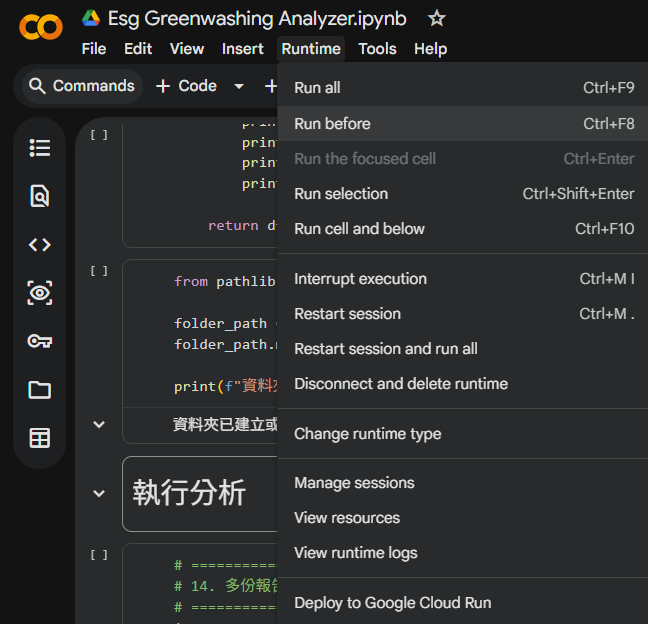

點擊視窗最左側 檔案的圖示, 點擊後應該會是如下的樣子

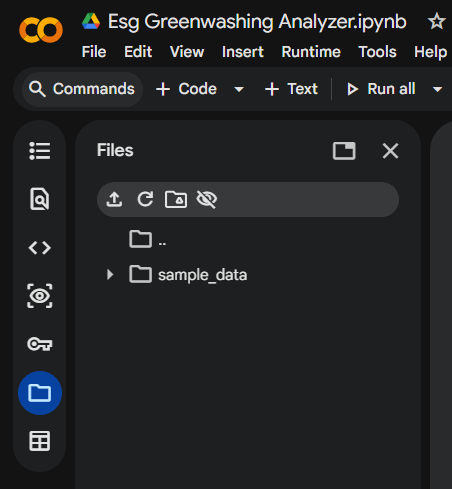

請先確保待分析的報告書的檔名都正確包含了 報告書的年份 (西元年)

點擊兩個點的那個資料夾( .. ), 點擊名為 content 的資料夾, 點擊 input_reports 這個資料夾旁邊的三個點 (把游標移到資料夾上應該就會看到豎著的三個點), 點選 upload, 將所有待分析的報告書都上傳到這個資料夾裡

點擊這個cell底下的 #14 旁的 像播放的按鈕

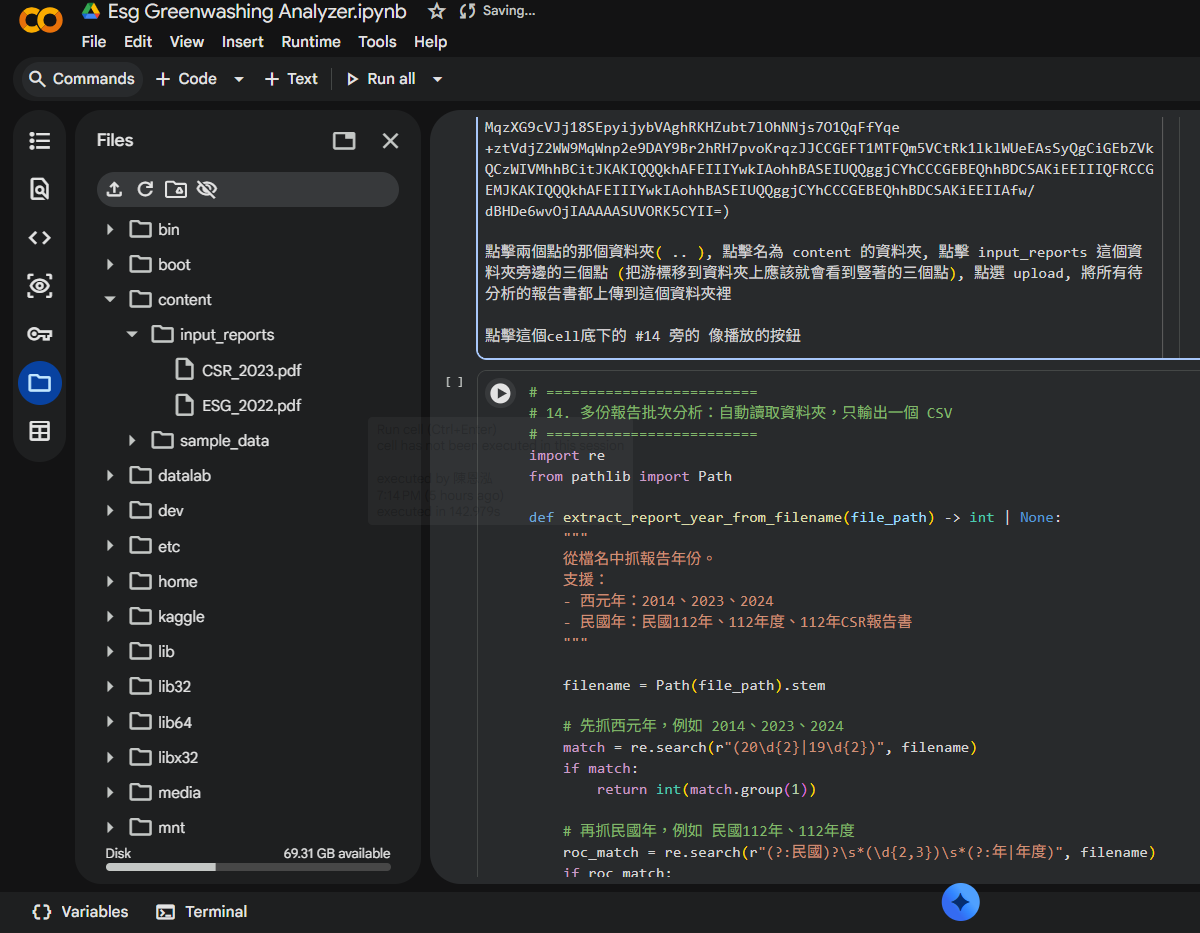

等待程式執行完畢

In [ ]:
# =========================
# A. 檔名與年份工具
# =========================
def extract_report_year_from_filename(file_path) -> int | None:
    """
    從檔名中抓報告年份。
    支援：
    - 西元年：2014、2023、2024
    - 民國年：民國112年、112年度、112年CSR報告書
    """
    filename = Path(file_path).stem

    # 先抓西元年，例如 2014、2023、2024
    match = re.search(r"(20\d{2}|19\d{2})", filename)
    if match:
        return int(match.group(1))

    # 再抓民國年，例如 民國112年、112年度
    roc_match = re.search(r"(?:民國)?\s*(\d{2,3})\s*(?:年|年度)", filename)
    if roc_match:
        roc_year = int(roc_match.group(1))
        if roc_year >= 80:
            return roc_year + 1911

    return None


def safe_filename(text: str) -> str:
    """
    清理檔名，避免 Windows / macOS 不適合的特殊符號。
    """
    text = str(text).strip()
    text = re.sub(r'[\\/:*?"<>|]', "_", text)
    text = re.sub(r"\s+", "_", text)
    return text if text else "company"


def safe_float(x, digits: int = 2):
    """
    將數值安全轉成 float 並四捨五入；若無法轉換則回傳 None。
    """
    try:
        if pd.isna(x):
            return None
        return round(float(x), digits)
    except Exception:
        return None


# =========================
# B. 整體風險等級與敘述產生
# =========================
def get_overall_risk_level(score: float | int | None) -> str:
    """
    報告層級的整體風險等級。

    注意：這是「整份報告平均風險」的分級，
    因為平均值通常會比單一段落風險低，所以門檻比段落層級略低。
    """
    if score is None or pd.isna(score):
        return "Unknown"
    score = float(score)
    if score >= 60:
        return "High"
    elif score >= 30:
        return "Medium"
    else:
        return "Low"


def generate_report_analysis(summary: dict) -> str:
    """
    依據報告層級指標，產生整篇報告的分析敘述。
    不使用額外 LLM，採規則式模板，確保輸出穩定且零成本。
    """
    risk_score = summary.get("overall_greenwashing_risk_score")
    risk_level = summary.get("overall_risk_level")
    avg_commitment = summary.get("avg_commitment_score")
    avg_evidence = summary.get("avg_evidence_score")
    avg_credibility = summary.get("avg_credibility_score")
    high_chunks = summary.get("high_risk_chunks") or 0
    high_ratio = summary.get("high_risk_ratio") or 0
    n_chunks = summary.get("n_chunks") or 0

    parts = []

    if risk_level == "High":
        parts.append("整體而言，這份報告具有較高程度的潛在漂綠風險。")
    elif risk_level == "Medium":
        parts.append("整體而言，這份報告具有中等程度的潛在漂綠風險。")
    elif risk_level == "Low":
        parts.append("整體而言，這份報告的潛在漂綠風險相對較低。")
    else:
        parts.append("整體而言，這份報告的漂綠風險等級無法判定。")

    if risk_score is not None:
        parts.append(f"整體漂綠風險分數為 {safe_float(risk_score)} 分。")

    if avg_commitment is not None and avg_evidence is not None:
        diff_ce = float(avg_commitment) - float(avg_evidence)
        if diff_ce >= 20:
            parts.append("報告中的平均承諾分數明顯高於平均證據分數，表示文本較強調永續願景、目標或承諾，但具體量化支持相對不足。")
        elif diff_ce >= 10:
            parts.append("報告中的平均承諾分數高於平均證據分數，表示永續目標與願景敘述較多，仍建議檢視其量化證據是否充分。")
        elif diff_ce <= -10:
            parts.append("報告中的平均證據分數高於平均承諾分數，表示文本中相對較多具體數據或成果資訊。")
        else:
            parts.append("報告中的平均承諾分數與平均證據分數差距不大，代表永續目標敘述與具體支持程度相對接近。")

    if avg_credibility is not None:
        if float(avg_credibility) < 40:
            parts.append("平均可信度分數偏低，部分 ESG 敘述可能缺乏具體時間、方法、量化依據或可檢查資訊。")
        elif float(avg_credibility) < 60:
            parts.append("平均可信度分數屬於中等，部分段落具備一定資訊基礎，但仍有進一步補強揭露品質的空間。")
        else:
            parts.append("平均可信度分數較高，代表多數 ESG 敘述相對具體且較容易被檢查。")

    if n_chunks > 0:
        if high_chunks >= 1:
            parts.append(f"報告中共有 {high_chunks} 個段落被判定為高漂綠風險，建議進一步人工檢視前幾個高風險段落。")
        else:
            parts.append("報告中沒有段落被判定為高漂綠風險。")

        if high_ratio >= 0.10:
            parts.append("高風險段落占比達到需要注意的程度。")
        elif high_ratio > 0:
            parts.append("高風險段落占比不高，但仍應檢視其具體內容。")

    return "".join(parts)


# =========================
# C. 前 5 高風險段落敘述產生
# =========================
def generate_paragraph_analysis(row: pd.Series) -> str:
    """
    依據單一段落的分數與特徵，產生可直接放到網頁 demo 的段落分析敘述。
    """
    risk = row.get("Greenwashing Risk", np.nan)
    risk_level = row.get("Risk Level", "Unknown")
    commitment = row.get("Commitment Score", np.nan)
    evidence = row.get("Evidence Score", np.nan)
    credibility = row.get("Credibility Score", np.nan)
    explanation = row.get("Explanation", "")

    parts = []

    # 風險總述
    if risk_level == "High":
        parts.append(f"此段落被判定為高漂綠風險，風險分數為 {safe_float(risk)}。")
    elif risk_level == "Medium":
        parts.append(f"此段落被判定為中等漂綠風險，風險分數為 {safe_float(risk)}。")
    elif risk_level == "Low":
        parts.append(f"此段落被判定為低漂綠風險，風險分數為 {safe_float(risk)}。")
    else:
        parts.append(f"此段落風險等級無法判定，風險分數為 {safe_float(risk)}。")

    # 承諾程度
    if pd.notna(commitment):
        if commitment >= 70:
            parts.append("段落具有較強的永續承諾、目標或願景敘述。")
        elif commitment >= 40:
            parts.append("段落具有一定程度的永續承諾或目標語氣。")
        else:
            parts.append("段落中的永續承諾或目標語氣相對較弱。")

    # 證據支持
    if pd.notna(evidence):
        if evidence < 40:
            parts.append("具體量化證據分數偏低，可能缺少明確數據、百分比、年份、單位或成果指標。")
        elif evidence < 60:
            parts.append("具體量化證據分數屬於中等，段落可能有部分數據或成果資訊，但仍不算充分。")
        else:
            parts.append("具體量化證據分數較高，段落中包含較多數據、指標或具體成果。")

    # 可信度
    if pd.notna(credibility):
        if credibility < 40:
            parts.append("可信度分數偏低，表示段落可能較缺乏可檢查資訊或第三方驗證訊號。")
        elif credibility < 60:
            parts.append("可信度分數屬於中等，段落有部分具體資訊，但仍有補強空間。")
        else:
            parts.append("可信度分數較高，段落敘述相對具體且較容易被檢查。")

    # 原本 Explanation 補充
    if isinstance(explanation, str) and explanation.strip():
        parts.append(f"補充判斷：{explanation.strip()}")

    return "".join(parts)


def add_top_risk_columns(summary: dict, df: pd.DataFrame, top_n: int = 5) -> dict:
    """
    將 df 中漂綠風險最高的前 top_n 段落展開成 summary 的欄位。
    維持 CSV 一份報告一列的結構。
    """
    top_df = df.sort_values("Greenwashing Risk", ascending=False).head(top_n).reset_index(drop=True)

    for i in range(1, top_n + 1):
        if i <= len(top_df):
            row = top_df.iloc[i - 1]
            summary[f"top{i}_chunk_id"] = int(row["chunk_id"]) if pd.notna(row.get("chunk_id")) else None
            summary[f"top{i}_risk_score"] = safe_float(row.get("Greenwashing Risk"))
            summary[f"top{i}_risk_level"] = row.get("Risk Level")
            summary[f"top{i}_commitment_score"] = safe_float(row.get("Commitment Score"))
            summary[f"top{i}_evidence_score"] = safe_float(row.get("Evidence Score"))
            summary[f"top{i}_credibility_score"] = safe_float(row.get("Credibility Score"))
            summary[f"top{i}_analysis"] = generate_paragraph_analysis(row)
            summary[f"top{i}_text"] = row.get("text")
        else:
            summary[f"top{i}_chunk_id"] = None
            summary[f"top{i}_risk_score"] = None
            summary[f"top{i}_risk_level"] = None
            summary[f"top{i}_commitment_score"] = None
            summary[f"top{i}_evidence_score"] = None
            summary[f"top{i}_credibility_score"] = None
            summary[f"top{i}_analysis"] = None
            summary[f"top{i}_text"] = None

    return summary


def add_empty_top_risk_columns(summary: dict, top_n: int = 5) -> dict:
    """
    分析失敗時，也補齊 top1 ~ top5 欄位，避免 CSV 欄位不一致。
    """
    for i in range(1, top_n + 1):
        summary[f"top{i}_chunk_id"] = None
        summary[f"top{i}_risk_score"] = None
        summary[f"top{i}_risk_level"] = None
        summary[f"top{i}_commitment_score"] = None
        summary[f"top{i}_evidence_score"] = None
        summary[f"top{i}_credibility_score"] = None
        summary[f"top{i}_analysis"] = None
        summary[f"top{i}_text"] = None
    return summary


# =========================
# D. 新版批次分析：只輸出一個 CSV，一份報告一列，含前 5 高風險段落
# =========================
def analyze_reports_from_folder(
    input_dir: str = "/content/input_reports",
    output_dir: str = "/content",
    file_extensions: tuple = (".pdf", ".txt", ".md"),
    load_model_once: bool = True,
    ask_company_name: bool = True,
    company_name: str | None = None,
    auto_download: bool = True,
    top_n: int = 5,
    sort_by: str = "year"
) -> pd.DataFrame:
    """
    自動讀取 input_dir 資料夾中的所有報告檔案，逐份執行 analyze_report()。

    輸出：
    - 只輸出一份 CSV
    - 一份報告一列
    - 每列包含整體分數、整篇分析敘述、前 5 高風險段落內容與敘述

    CSV 檔名格式：
    公司名稱_最早報告年_最晚報告年_batch_summary.csv
    """
    input_path = Path(input_dir)
    output_path = Path(output_dir)

    if not input_path.exists():
        raise FileNotFoundError(f"找不到資料夾：{input_dir}")

    output_path.mkdir(parents=True, exist_ok=True)

    # 自動抓資料夾裡所有指定格式檔案
    file_paths = []
    for ext in file_extensions:
        file_paths.extend(input_path.glob(f"*{ext}"))
        file_paths.extend(input_path.glob(f"*{ext.upper()}"))

    file_paths = sorted(set(file_paths))

    if len(file_paths) == 0:
        raise ValueError(f"在 {input_dir} 裡找不到可分析的報告檔案：{file_extensions}")

    print(f"找到 {len(file_paths)} 份報告：")
    for f in file_paths:
        print(" -", f.name)

    # 批次分析時模型只載入一次
    if load_model_once:
        print("\n==============================")
        print("Loading zero-shot model once for batch analysis")
        print("==============================")
        clf = load_zero_shot_pipeline()
    else:
        clf = None

    summaries = []

    for file_path in file_paths:
        report_name = file_path.stem
        report_year = extract_report_year_from_filename(file_path)

        print("\n==============================")
        print("Analyzing:", file_path)
        print("Detected year:", report_year)
        print("==============================")

        try:
            df = analyze_report(
                str(file_path),
                clf=clf,
                save_outputs=False
            )

            # 保險：確保 df 依照 Greenwashing Risk 由高到低排序
            df = df.sort_values("Greenwashing Risk", ascending=False).reset_index(drop=True)

            overall_risk_score = df["Greenwashing Risk"].mean()
            overall_risk_level = get_overall_risk_level(overall_risk_score)

            summary = {
                "file": str(file_path),
                "report_name": report_name,
                "year": report_year,
                "n_chunks": len(df),

                # 整體報告層級分數
                "overall_greenwashing_risk_score": safe_float(overall_risk_score),
                "overall_risk_level": overall_risk_level,
                "avg_commitment_score": safe_float(df["Commitment Score"].mean()),
                "avg_evidence_score": safe_float(df["Evidence Score"].mean()),
                "avg_credibility_score": safe_float(df["Credibility Score"].mean()),

                # 最高風險與前 5 高風險平均
                "max_greenwashing_risk": safe_float(df["Greenwashing Risk"].max()),
                "top5_avg_greenwashing_risk": safe_float(df.head(top_n)["Greenwashing Risk"].mean()),

                # 各風險等級段落數
                "high_risk_chunks": int((df["Risk Level"] == "High").sum()),
                "medium_risk_chunks": int((df["Risk Level"] == "Medium").sum()),
                "low_risk_chunks": int((df["Risk Level"] == "Low").sum()),

                # 各風險等級比例
                "high_risk_ratio": safe_float((df["Risk Level"] == "High").mean(), digits=4),
                "medium_risk_ratio": safe_float((df["Risk Level"] == "Medium").mean(), digits=4),
                "low_risk_ratio": safe_float((df["Risk Level"] == "Low").mean(), digits=4),

                "error": ""
            }

            # 整篇報告分析敘述
            summary["report_analysis"] = generate_report_analysis(summary)

            # 前 5 高風險段落展開欄位
            summary = add_top_risk_columns(summary, df, top_n=top_n)

            summaries.append(summary)

        except Exception as e:
            print(f"分析失敗：{file_path.name}")
            print("錯誤原因：", e)

            summary = {
                "file": str(file_path),
                "report_name": report_name,
                "year": report_year,
                "n_chunks": None,
                "overall_greenwashing_risk_score": None,
                "overall_risk_level": "Unknown",
                "avg_commitment_score": None,
                "avg_evidence_score": None,
                "avg_credibility_score": None,
                "max_greenwashing_risk": None,
                "top5_avg_greenwashing_risk": None,
                "high_risk_chunks": None,
                "medium_risk_chunks": None,
                "low_risk_chunks": None,
                "high_risk_ratio": None,
                "medium_risk_ratio": None,
                "low_risk_ratio": None,
                "report_analysis": f"此報告分析失敗，錯誤原因：{e}",
                "error": str(e)
            }

            summary = add_empty_top_risk_columns(summary, top_n=top_n)
            summaries.append(summary)

    summary_df = pd.DataFrame(summaries)

    # 排序：預設依年份排序；若年份不足，則依整體漂綠風險排序
    if sort_by == "year" and "year" in summary_df.columns:
        summary_df = summary_df.sort_values(
            ["year", "overall_greenwashing_risk_score"],
            ascending=[True, False],
            na_position="last"
        )
    else:
        summary_df = summary_df.sort_values(
            "overall_greenwashing_risk_score",
            ascending=False,
            na_position="last"
        )

    # 自動計算最早與最晚報告年
    valid_years = pd.to_numeric(summary_df["year"], errors="coerce").dropna()
    if len(valid_years) > 0:
        start_year = str(int(valid_years.min()))
        end_year = str(int(valid_years.max()))
    else:
        start_year = "unknown"
        end_year = "unknown"

    # 公司名稱：可手動輸入，也可從參數傳入
    if ask_company_name and not company_name:
        print("\n==============================")
        print("請輸入輸出檔名資訊")
        print("==============================")
        company_name = input("請輸入公司名稱，例如 彰銀：").strip()

    if not company_name:
        company_name = "company"

    company_name = safe_filename(company_name)

    output_filename = f"{company_name}_{start_year}_{end_year}_batch_summary.csv"
    output_csv = output_path / output_filename

    # 只輸出一個 CSV
    summary_df.to_csv(output_csv, index=False, encoding="utf-8-sig")

    print("\n批次分析完成。")
    print("只輸出總表 CSV：", output_csv)
    print(f"報告年份範圍：{start_year} - {end_year}")

    # 自動下載 CSV
    if auto_download:
        try:
            from google.colab import files
            files.download(str(output_csv))
            print("已觸發下載。下載位置由瀏覽器設定決定。")
        except Exception as e:
            print("自動下載失敗，請到左側檔案區手動下載：", output_csv)
            print("錯誤原因：", e)

    return summary_df


# =========================
# E. 執行範例
# =========================
batch_summary = analyze_reports_from_folder(
    input_dir="/content/input_reports",
    output_dir="/content",
    ask_company_name=True,
    auto_download=True,
    top_n=5,
    sort_by="year"
)

batch_summary

#分析結果

跟隨程式指示輸入公司名稱, 以供程式命名輸出檔案

檔名會是這樣子: {你輸入的公司名稱}\_{偵測到的報告起始年}\_{偵測到的報告最後一年}_batch_summary.csv

範例: 台中銀行_2022_2023_batch_summary

檔案預設會自動下載, 檔案也存在左側 content 裡, 自動下載有問題的話就在左邊找到檔案手動下載 (點擊檔案旁邊的三個點 (把游標移到資料夾上應該就會看到豎著的三個點), 點選 Download)

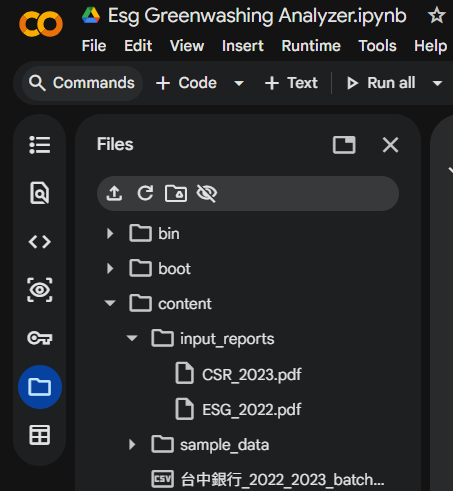

In [ ]:
# 清空資料夾內容
import shutil
from pathlib import Path

folder_path = '/content/input_reports'
print("清空 /content/input_reports：")

path = Path('/content/input_reports')

if not path.exists():
    print(f"找不到資料夾：{folder_path}")
elif not path.is_dir():
    print(f"這不是資料夾：{folder_path}")
else:
    print(
        f"刪除資料夾內所有內容"
    )

    deleted_files = 0
    deleted_folders = 0

    for item in path.iterdir():
        if item.is_file() or item.is_symlink():
            item.unlink()
            deleted_files += 1
        elif item.is_dir():
            shutil.rmtree(item)
            deleted_folders += 1

    print(f"已清空資料夾內容：{folder_path}")
    print(f"刪除檔案數：{deleted_files}")
    print(f"刪除子資料夾數：{deleted_folders}")


#其他 (應該用不到的一些程式)

In [ ]:
# 12. Colab 使用範例
# =========================
# 方法 A：上傳 PDF
from google.colab import files
# uploaded = files.upload()
# input_file = list(uploaded.keys())[0]
input_file = "/content/input_reports/CSR_2017.pdf"
result_df = analyze_report(input_file, output_prefix="my_esg_report")
result_df.head(20)

# 方法 B：若檔案已在 Google Drive
# from google.colab import drive
# drive.mount('/content/drive')
# input_file = "/content/drive/MyDrive/your_report.pdf"
# result_df = analyze_report(input_file, output_prefix="company_esg_2024")
# result_df.head(20)


In [ ]:
'''
from pathlib import Path
from google.colab import files

report_name = Path(input_file).stem
output_csv = f"/content/{report_name}_analysis.csv"

result_df.to_csv(output_csv, index=False, encoding="utf-8-sig")

files.download(output_csv)
'''
#---

from pathlib import Path
from google.colab import files
import pandas as pd

report_name = Path(input_file).stem
output_csv = f"/content/{report_name}_summary_one_row.csv"

# 把單份報告 result_df 統整成一列
summary_df = pd.DataFrame([{
    "file": input_file,
    "company_or_report": report_name,
    "n_chunks": len(result_df),

    "avg_commitment_score": result_df["Commitment Score"].mean(),
    "avg_evidence_score": result_df["Evidence Score"].mean(),
    "avg_credibility_score": result_df["Credibility Score"].mean(),
    "avg_greenwashing_risk": result_df["Greenwashing Risk"].mean(),

    "max_greenwashing_risk": result_df["Greenwashing Risk"].max(),
    "top10_avg_greenwashing_risk": result_df.head(10)["Greenwashing Risk"].mean(),

    "high_risk_chunks": int((result_df["Risk Level"] == "High").sum()),
    "medium_risk_chunks": int((result_df["Risk Level"] == "Medium").sum()),
    "low_risk_chunks": int((result_df["Risk Level"] == "Low").sum()),

    "high_risk_ratio": float((result_df["Risk Level"] == "High").mean()),
    "medium_risk_ratio": float((result_df["Risk Level"] == "Medium").mean()),
    "low_risk_ratio": float((result_df["Risk Level"] == "Low").mean()),

    "top_risk_chunk_id": int(result_df.iloc[0]["chunk_id"]),
    "top_risk_score": float(result_df.iloc[0]["Greenwashing Risk"]),
    "top_risk_level": result_df.iloc[0]["Risk Level"],
    "top_risk_explanation": result_df.iloc[0]["Explanation"],
    "top_risk_text": result_df.iloc[0]["text"],
}])

# 輸出一列摘要 CSV
summary_df.to_csv(output_csv, index=False, encoding="utf-8-sig")

files.download(output_csv)

In [ ]:
# =========================
# 15. 輸出人工標註驗證檔案
# =========================
def export_human_validation_file(
    df: pd.DataFrame,
    output_path: str = "human_validation_sample.xlsx",
    n_per_level: int = 30,
    random_state: int = 42,
    include_model_scores: bool = True,
    blind_review: bool = False,
) -> pd.DataFrame:
    """
    從模型輸出結果中，依 High / Medium / Low 風險各抽 n_per_level 筆，
    輸出給人工標註用的 Excel。

    人工標註欄位：
    - Human Commitment: 0/1
    - Human Evidence: 0/1
    - Human Credibility: 0/1
    - Human Risk Level: 1/2/3
        1 = Low 低風險
        2 = Medium 中風險
        3 = High 高風險
    """

    df = df.copy()

    if "Risk Level" not in df.columns:
        raise ValueError("df 裡找不到 'Risk Level' 欄位，請確認你傳入的是 analyze_report() 的輸出結果。")

    samples = []

    for level in ["High", "Medium", "Low"]:
        sub = df[df["Risk Level"] == level].copy()

        if len(sub) == 0:
            print(f"提醒：沒有 {level} 風險段落可抽樣。")
            continue

        sample_n = min(n_per_level, len(sub))
        sampled = sub.sample(n=sample_n, random_state=random_state)
        samples.append(sampled)

        print(f"{level}: 抽出 {sample_n} 筆 / 原本 {len(sub)} 筆")

    if len(samples) == 0:
        raise ValueError("沒有抽出任何樣本，請檢查 Risk Level 欄位內容。")

    validation_df = pd.concat(samples, ignore_index=True)

    # 打亂順序，避免人工標註者知道前面都是 High、中間都是 Medium
    validation_df = validation_df.sample(frac=1, random_state=random_state).reset_index(drop=True)

    # 建立人工標註欄位
    validation_df.insert(0, "sample_id", range(1, len(validation_df) + 1))
    validation_df["Human Commitment"] = ""       # 0/1：是否有明確 ESG 承諾或目標
    validation_df["Human Evidence"] = ""         # 0/1：是否有量化數據或具體證據
    validation_df["Human Credibility"] = ""      # 0/1：是否具體、可驗證
    validation_df["Human Risk Level"] = ""       # 1/2/3：1=Low，2=Medium，3=High
    validation_df["Human Note"] = ""             # 人工備註

    base_cols = [
        "sample_id",
        "chunk_id",
        "text",
        "Human Commitment",
        "Human Evidence",
        "Human Credibility",
        "Human Risk Level",
        "Human Note",
    ]

    model_cols = [
        "Risk Level",
        "Greenwashing Risk",
        "Commitment Score",
        "Evidence Score",
        "Credibility Score",
        "Explanation",
        "number_count",
        "year_count",
        "has_percent",
        "has_unit",
        "has_year",
        "commitment_kw_count",
        "evidence_kw_count",
        "vague_kw_count",
        "promotional_kw_count",
        "tfidf_top_terms",
    ]

    if blind_review:
        final_cols = base_cols
    else:
        if include_model_scores:
            final_cols = base_cols + [c for c in model_cols if c in validation_df.columns]
        else:
            final_cols = base_cols + ["Explanation"] if "Explanation" in validation_df.columns else base_cols

    validation_df = validation_df[[c for c in final_cols if c in validation_df.columns]]

    instruction_df = pd.DataFrame({
        "欄位": [
            "Human Commitment",
            "Human Evidence",
            "Human Credibility",
            "Human Risk Level",
            "Human Note",
        ],
        "填寫方式": [
            "填 1 或 0。1 = 段落有明確 ESG 承諾、目標、改善方向或期限；0 = 沒有。",
            "填 1 或 0。1 = 段落有數字、百分比、單位、KPI、第三方查證或具體成果；0 = 沒有。",
            "填 1 或 0。1 = 段落有具體時間、範圍、方法、基準年、查證機制，足以被驗證；0 = 模糊或難以驗證。",
            "填 1、2 或 3。1 = Low 低風險；2 = Medium 中風險；3 = High 高風險。",
            "可寫人工判斷理由，例如：有 2030 目標但缺少基準年、只有口號沒有數據等。",
        ]
    })

    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        validation_df.to_excel(writer, sheet_name="human_labeling", index=False)
        instruction_df.to_excel(writer, sheet_name="labeling_instruction", index=False)

        workbook = writer.book
        ws = workbook["human_labeling"]
        ws.freeze_panes = "A2"

        # 調整欄寬
        for col in ws.columns:
            col_letter = col[0].column_letter
            header = col[0].value

            if header == "text":
                ws.column_dimensions[col_letter].width = 80
            elif header in ["Explanation", "Human Note"]:
                ws.column_dimensions[col_letter].width = 45
            else:
                ws.column_dimensions[col_letter].width = 18

        # 加上 Excel 下拉選單，避免人工標註打錯
        from openpyxl.worksheet.datavalidation import DataValidation

        max_row = len(validation_df) + 1

        binary_validation = DataValidation(
            type="list",
            formula1='"0,1"',
            allow_blank=True
        )

        risk_validation = DataValidation(
            type="list",
            formula1='"1,2,3"',
            allow_blank=True
        )

        ws.add_data_validation(binary_validation)
        ws.add_data_validation(risk_validation)

        # 找欄位位置
        header_to_col = {cell.value: cell.column_letter for cell in ws[1]}

        for col_name in ["Human Commitment", "Human Evidence", "Human Credibility"]:
            if col_name in header_to_col:
                col_letter = header_to_col[col_name]
                binary_validation.add(f"{col_letter}2:{col_letter}{max_row}")

        if "Human Risk Level" in header_to_col:
            col_letter = header_to_col["Human Risk Level"]
            risk_validation.add(f"{col_letter}2:{col_letter}{max_row}")

        ws2 = workbook["labeling_instruction"]
        ws2.column_dimensions["A"].width = 25
        ws2.column_dimensions["B"].width = 100

    print(f"已輸出人工標註檔案：{output_path}")
    print("Human Risk Level 填寫規則：1 = Low，2 = Medium，3 = High")

    return validation_df


# 使用範例：
validation_df = export_human_validation_file(
    result_df,
    output_path="human_validation_sample.xlsx",
    n_per_level=5,
    blind_review=False
)

from google.colab import files
files.download("human_validation_sample.xlsx")

In [ ]:
from google.colab import files

uploaded = files.upload()
labeled_file = list(uploaded.keys())[0]

print("已上傳：", labeled_file)

In [ ]:
# =========================
# 16. 人工標註完成後：計算驗證指標
# =========================
def evaluate_human_validation(
    labeled_file: str = "human_validation_sample_labeled.xlsx",
    commitment_threshold: float = 60,
    evidence_threshold: float = 60,
    credibility_threshold: float = 60,
    risk_threshold_low: float = 40,
    risk_threshold_high: float = 70,
) -> pd.DataFrame:
    """
    讀取人工標註完成的 Excel，計算 Accuracy / Precision / Recall / F1。

    人工標註格式：
    - Human Commitment: 0/1
    - Human Evidence: 0/1
    - Human Credibility: 0/1
    - Human Risk Level: 1/2/3
        1 = Low
        2 = Medium
        3 = High

    注意：
    這個檔案需要保留模型分數欄位，
    所以 blind_review=True 的檔案不能直接用這個函數。
    """
    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        classification_report,
        confusion_matrix
    )

    df = pd.read_excel(labeled_file, sheet_name="human_labeling")

    required_cols = [
        "Human Commitment",
        "Human Evidence",
        "Human Credibility",
        "Human Risk Level",
        "Commitment Score",
        "Evidence Score",
        "Credibility Score",
        "Greenwashing Risk",
    ]

    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"缺少欄位：{missing}")

    # 人工標註欄位轉成數字
    df["Human Commitment"] = pd.to_numeric(df["Human Commitment"], errors="coerce")
    df["Human Evidence"] = pd.to_numeric(df["Human Evidence"], errors="coerce")
    df["Human Credibility"] = pd.to_numeric(df["Human Credibility"], errors="coerce")
    df["Human Risk Level"] = pd.to_numeric(df["Human Risk Level"], errors="coerce")

    # 模型分數轉成 0/1
    df["Pred Commitment"] = (df["Commitment Score"] >= commitment_threshold).astype(int)
    df["Pred Evidence"] = (df["Evidence Score"] >= evidence_threshold).astype(int)
    df["Pred Credibility"] = (df["Credibility Score"] >= credibility_threshold).astype(int)

    # 模型 Greenwashing Risk 轉成 1/2/3
    # 1 = Low, 2 = Medium, 3 = High
    def pred_risk_level(score):
        if score >= risk_threshold_high:
            return 3
        elif score >= risk_threshold_low:
            return 2
        else:
            return 1

    df["Pred Risk Level Numeric"] = df["Greenwashing Risk"].apply(pred_risk_level)

    # Commitment / Evidence / Credibility 三個二元任務
    for task in ["Commitment", "Evidence", "Credibility"]:
        y_true = df[f"Human {task}"]
        y_pred = df[f"Pred {task}"]

        valid = y_true.notna()

        print("=" * 60)
        print(task)
        print("有效標註數：", int(valid.sum()))

        if valid.sum() == 0:
            print("沒有有效標註，跳過。")
            continue

        print("Accuracy:", round(accuracy_score(y_true[valid], y_pred[valid]), 4))
        print("Precision:", round(precision_score(y_true[valid], y_pred[valid], zero_division=0), 4))
        print("Recall:", round(recall_score(y_true[valid], y_pred[valid], zero_division=0), 4))
        print("F1:", round(f1_score(y_true[valid], y_pred[valid], zero_division=0), 4))

        print("Confusion Matrix:")
        print(confusion_matrix(
            y_true[valid],
            y_pred[valid],
            labels=[0, 1]
        ))

    # Greenwashing Risk Level 三分類任務
    print("=" * 60)
    print("Greenwashing Risk Level")

    y_true = df["Human Risk Level"]
    y_pred = df["Pred Risk Level Numeric"]

    valid = y_true.notna()

    print("有效標註數：", int(valid.sum()))

    if valid.sum() == 0:
        print("沒有有效標註，跳過。")
    else:
        print(classification_report(
            y_true[valid],
            y_pred[valid],
            labels=[1, 2, 3],
            target_names=["Low(1)", "Medium(2)", "High(3)"],
            zero_division=0
        ))

        print("Confusion Matrix:")
        print(confusion_matrix(
            y_true[valid],
            y_pred[valid],
            labels=[1, 2, 3]
        ))

    return df

eval_df = evaluate_human_validation(labeled_file)

In [ ]:
# 13. 顯示高風險段落
# =========================
def show_top_risks(df: pd.DataFrame, n: int = 10):
    cols = [
        "chunk_id", "Risk Level", "Greenwashing Risk",
        "Commitment Score", "Evidence Score", "Credibility Score",
        "Explanation", "text"
    ]
    display(df[cols].head(n))

# 執行分析後可用：
show_top_risks(result_df, 10)


In [ ]:
!pip -q install transformers accelerate sentencepiece

from transformers import pipeline
import shutil
from google.colab import files

MODEL_NAME = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
OUTPUT_DIR = "zero_shot_model"

clf = pipeline(
    "zero-shot-classification",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME
)

clf.model.save_pretrained(OUTPUT_DIR)
clf.tokenizer.save_pretrained(OUTPUT_DIR)

shutil.make_archive("zero_shot_model", "zip", OUTPUT_DIR)
files.download("zero_shot_model.zip")
